In [1]:
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt

import Minimal_Model_1D as M

In [2]:
###defining constants##

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

Checking convergence for a width of 100 nm

In [ ]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 1000        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

In [ ]:
K = 4

Tot = 20

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    H = D.H_sys(PHI, so='cu')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)

In [ ]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [ ]:
Ep2 = Ep[:,3]

In [ ]:

for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

checking convergence for width of 10 nm

In [ ]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 10            # Width in nm
ALPHAT = 1000        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

K = 4

Tot = 30

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    H = D.H_sys(PHI, so='cu')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [ ]:
Ep2 = Ep[:,3]


for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

Convergence lengths for cubic SO of 1000 meV-nm^3, weak link length of 300 nm and chemical potential of 1+OMEGA meV is:
for Ly = 100 nm ~ 1600 nm SC on both sides
for Ly = 10 nm ~ 2000 nm of SC on both sides

Plotting E vs Phi for 1000 meV nm^3 cubic SOC

In [ ]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 10           # Width in nm
ALPHAT = 1000        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM
#PHI = 0.0*np.pi 
#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands



In [ ]:

PHI = np.linspace(-1*np.pi,1*np.pi,21)
K = 8

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    #DELTA = np.array([1,0,1*cmath.exp(1j*PHI[i])])
    
    H = D.H_sys(PHI[i], so='cu' )
    #print(i)
    #+ KxSq(N, M, AX, PX, KX[i])
    #H = KxSqKy(N,M,AX,AY,PX,PY,KX[i],KY[i])
    #H = H.toarray()
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    #print('a')
    #print(E.shape)
    Ep[i,:] =np.sort(E)
    if i%20==0:
        print(i)


In [ ]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,:]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [ ]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 1000        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM
#PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1.5*OMEGA   #in between two subbands
MU_SM =  1.5* OMEGA   #in between two subbands



In [ ]:

PHI = np.linspace(-1*np.pi,1*np.pi,51)
K = 8

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='cu' )
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%20==0:
        print(i)

In [ ]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,:]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)


plt.show()

Now looking at the perturbative regime for cubic SO coupling

In [ ]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.5 + OMEGA   #in between two subbands
MU_SM =  0.5 + OMEGA   #in between two subbands

ALPHAT = np.linspace(10, 1200, 21)

K = 12

Ep_cu = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu
    
    if i%10==0:
        print(i)


In [ ]:
plt.rc('font', size=18)

f = plt.figure(figsize=(12, 24))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

Ep_lower = Ep_cu[:,K//2] 
Ep_upper = Ep_cu[:,K//2+1]


plt.subplot(3,1,1)
plt.plot((ALPHAT), (Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$\delta E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)


plt.subplot(3,1,2)
plt.plot((ALPHAT), (Ep_lower/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot((ALPHAT), (Ep_upper/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(3,1,3)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
#plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [ ]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

LY = 10           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.5 + OMEGA   #in between two subbands
MU_SM =  0.5 + OMEGA   #in between two subbands

ALPHAT = np.linspace(10, 1200, 21)

K = 8

Ep_cu = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu
    
    if i%10==0:
        print(i)


In [ ]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

Ep = Ep_cu[:,K//2]

plt.subplot(3,1,1)
plt.plot((ALPHAT), (Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$\delta E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)


plt.subplot(3,1,2)
plt.plot((ALPHAT), (Ep_lower/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(3,1,3)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
#plt.xlim(left=0)
plt.grid(True)


plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [ ]:
np.exp(6)

In [3]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(10, 200, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.5 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.5 + OMEGA

K = 8

Ep_cu = np.empty((LY.shape[0],K))
#Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fcu = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)


0
10
20
30
40
50


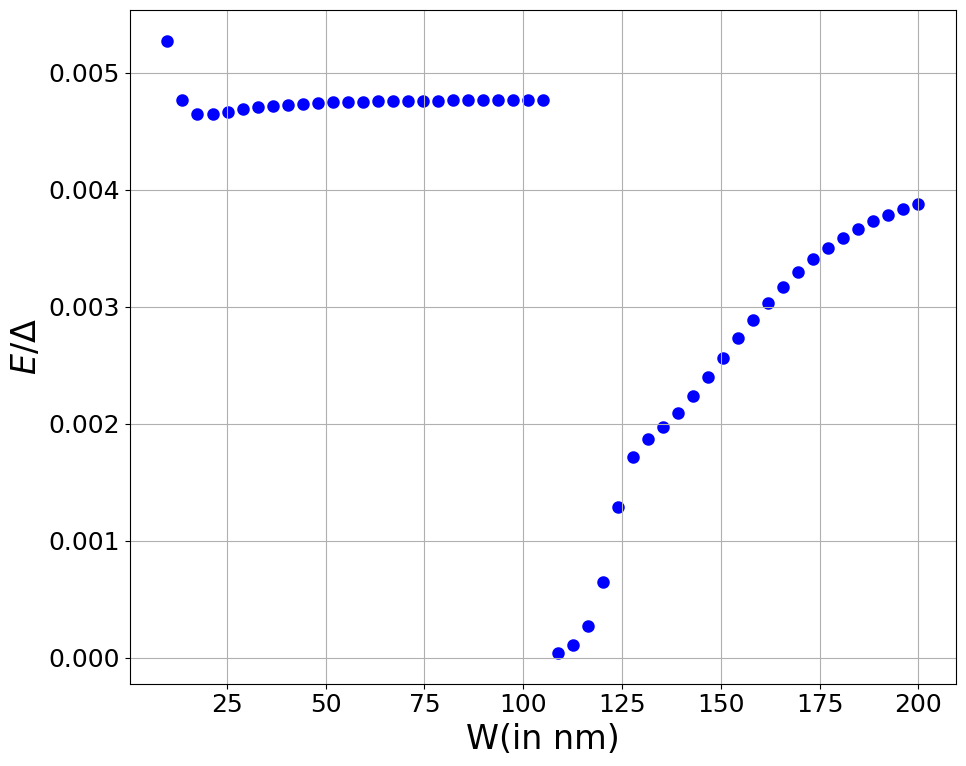

In [4]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

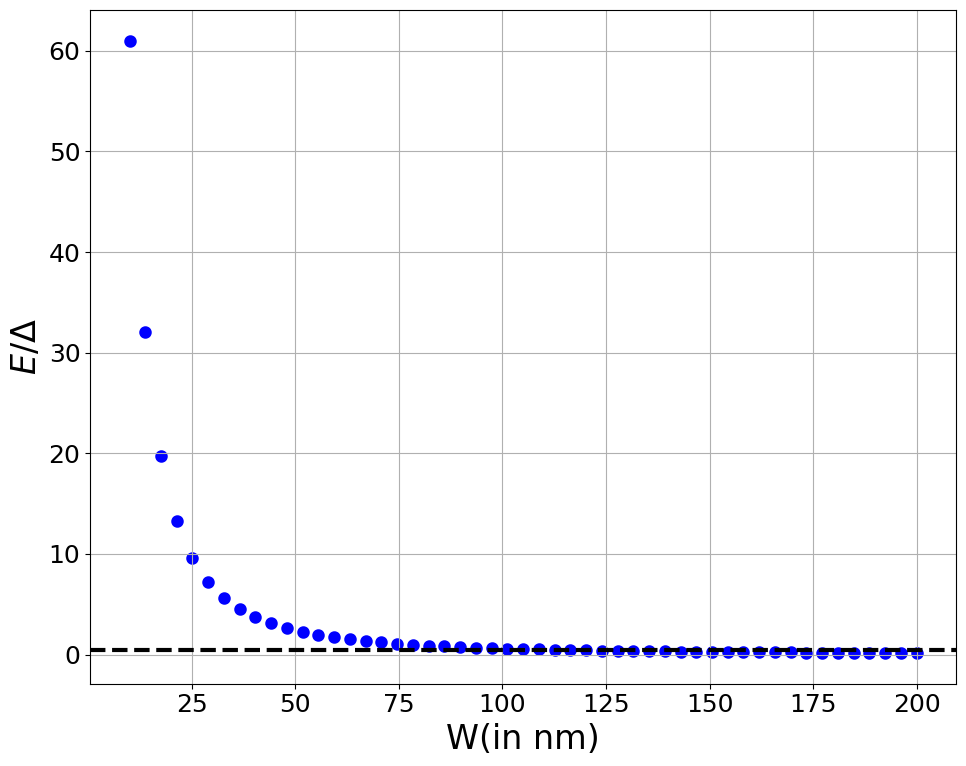

In [5]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY, OMEGA, lw=3 ,linestyle ='-' , color='blue')
plt.axhline(0.5, color='black', linestyle='dashed', lw=3)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

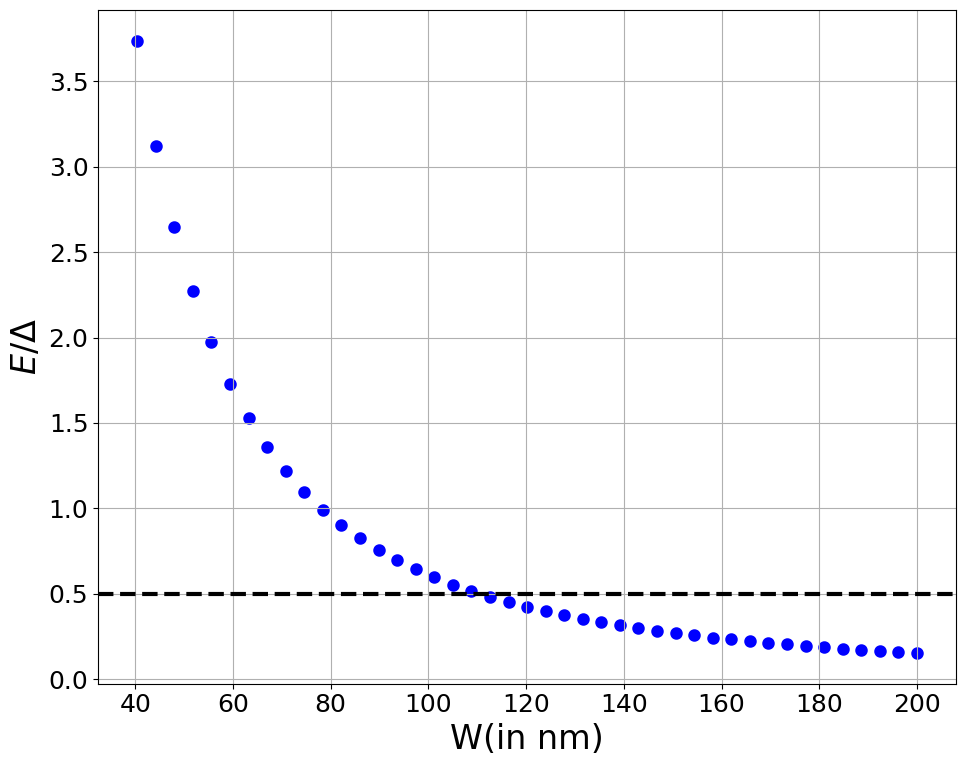

In [6]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY[8:], OMEGA[8:], lw=3 ,linestyle ='-' , color='blue')
plt.axhline(0.5, color='black', linestyle='dashed', lw=3)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

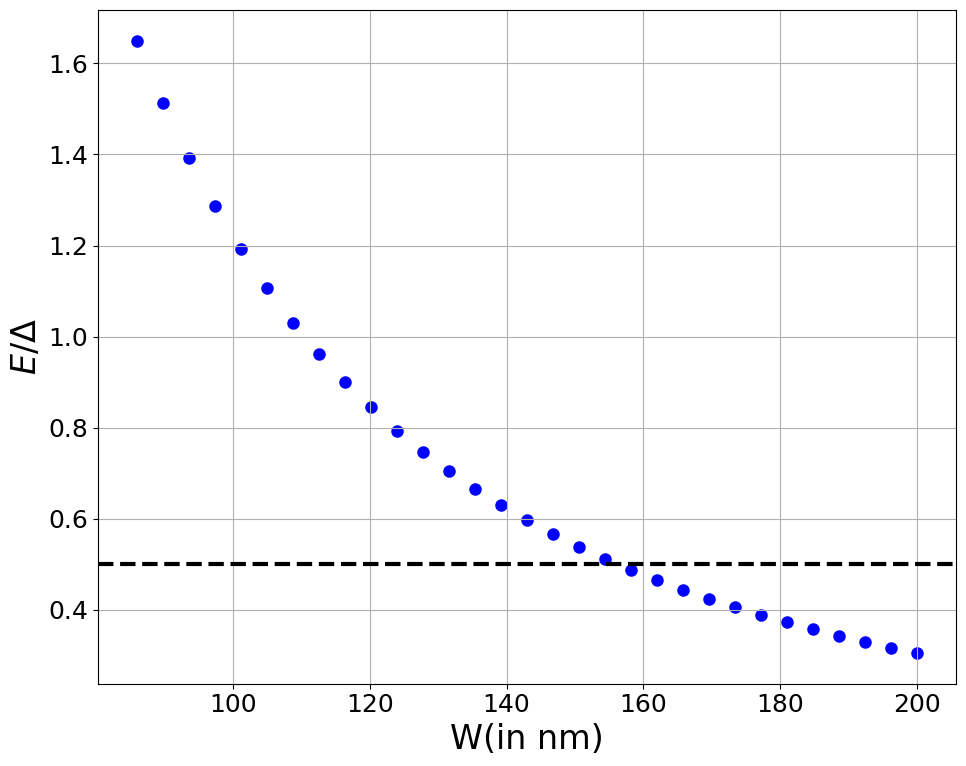

In [7]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY[20:], 2*OMEGA[20:], lw=3 ,linestyle ='-' , color='blue')
plt.axhline(0.5, color='black', linestyle='dashed', lw=3)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()